# Background

- **Author**: 待學生確認（本次對話者與分工尚未確認）
- **Created At**: 2026-11-09
- **Research Motivation and Context (why are we interested in the findings?)：** 依使用者指定，收入高州群為 MA、CO、DC，收入低州群為 NM、LA、MS；各群合併申請筆數後，比較四個收入組內白人、亞洲人與黑人的房貸核准率。使用 [高收入州群申請](../data/processed/state_MA-CO-DC_income_high_15_columns.csv)、[低收入州群申請](../data/processed/state_NM-LA-MS_income_low_15_columns.csv) 與 [final 州群個人收入門檻](../data/processed/[final]individual_income_quartiles_by_group.csv)。本文件的讀取驗證與樣本說明同時記錄輸入檢查。final 門檻的上游產生程式尚未確認；房貸檔的上游產生程式與資料年份未確認。州群排名依使用者指定，本次未重新驗證各州收入排名。
- **Main Findings and Takeaways：** 2026-11-15 已依 final 個人收入門檻從乾淨 kernel 重跑；有效申請 N=455,146，24 組結果已重新讀取核對。以下數字順序為高組／低組：Q1：白人 49.1%／61.2%、亞洲人 47.7%／55.6%、黑人 37.9%／40.6%；Q2：白人 48.9%／41.5%、亞洲人 36.8%／40.7%、黑人 30.6%／24.2%；Q3：白人 72.2%／65.1%、亞洲人 66.4%／64.3%、黑人 57.6%／47.0%；Q4：白人 85.2%／81.8%、亞洲人 84.6%／80.1%、黑人 71.3%／64.5%。圖表與結論均已更新，不能沿用舊家戶收入分組的結論。
- **Future Direction：** 確認房貸資料年份，並進一步納入州別、信用、貸款條件與機構差異；本次僅描述關聯。

更新日期：2026-11-15。依使用者指示改採 final 個人收入門檻；原家戶收入門檻的圖表與結果表由本次結果取代。個人收入與房貸申請 income 的所得範圍可能不同，本次僅依指定門檻分組，不主張兩者衡量完全一致。

2026-11-17：新增兩類核准率差異檢定（每圖 36 組）、Holm 校正與執行結果，詳見文件末段；全本已重新執行。


In [1]:
# Load packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
from IPython.display import Markdown
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Heiti TC', 'Arial Unicode MS', 'Noto Sans CJK TC'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('請從 econ-5166-student-kit 或其子目錄執行。')
INPUTS = {
 'state_MA-CO-DC_income_high_15_columns.csv': 'bd7902271c1d3efa36bdd0d19d2f456753f4117db9a55fab9f434709ac904c8b',
 'state_NM-LA-MS_income_low_15_columns.csv': 'e8ff73e6c26ce0189345feed4972863f3f91696249bc4a7c8fed37b0a0ccc7a4',
 '[final]individual_income_quartiles_by_group.csv': '9aec1cde45d1b069b71564e3f01228591aa18c302fa9c76b584f90378d4b1651',
}
def read_verified(name):
    path=(PROJECT_ROOT/'data/processed'/name).resolve()
    assert path.is_relative_to((PROJECT_ROOT/'data/processed').resolve())
    if hashlib.sha256(path.read_bytes()).hexdigest()!=INPUTS[name]:
        raise ValueError(f'資料版本變更，請先核對：{name}')
    return pd.read_csv(path)
groups=['High','Low']
states=[{'MA','CO','DC'},{'NM','LA','MS'}]
races=['White','Asian','Black or African American']
parts=[]
for name,group,expected_states,expected_n in zip(list(INPUTS)[:2],groups,states,[287517,182606]):
    frame=read_verified(name)
    assert frame.shape==(expected_n,15)
    assert {'state_code','derived_race','income','action_taken'}<=set(frame)
    assert set(frame.state_code)==expected_states
    assert set(frame.derived_race)==set(races)
    assert set(frame.action_taken)=={1,2,3}
    frame['state_group']=group
    parts.append(frame)
df=pd.concat(parts,ignore_index=True)
display(df.head(10))
final_source=read_verified('[final]individual_income_quartiles_by_group.csv')
assert len(final_source)==4 and final_source.Group.is_unique
assert set(final_source.Group)=={'Group A','Group B','Group C','Group D'}
assert np.isfinite(final_source[['Q1_Income','Q2_Income','Q3_Income']]).all().all()
assert (final_source.Q1_Income<final_source.Q2_Income).all() and (final_source.Q2_Income<final_source.Q3_Income).all()
selected=final_source.set_index('Group').loc[['Group C', 'Group D']].copy()
for code,expected in zip(['Group C', 'Group D'],[{'Massachusetts','Colorado','District of Columbia'},{'New Mexico','Louisiana','Mississippi'}]):
    assert {v.strip() for v in selected.loc[code,'Included_States'].split(';')}==expected
quartile_source=selected.reset_index().rename(columns={'Group':'final_group','Included_States':'included_states','Q1_Income':'Q1','Q2_Income':'Median','Q3_Income':'Q3'})
quartile_source['income_group']=groups
display(quartile_source)
cutoffs=quartile_source.set_index('income_group')[['Q1','Median','Q3']].reindex(groups).rename(columns={'Q1':'P25','Median':'P50','Q3':'P75'})/1000
cutoffs.index.name='state_group'
income_numeric=pd.to_numeric(df.income,errors='coerce')
finite=income_numeric.notna() & np.isfinite(income_numeric)
analysis=df.loc[finite].copy()
analysis['income']=income_numeric.loc[analysis.index]
analysis['approved']=analysis.action_taken.isin([1,2]).astype(int)
analysis['income_quartile']=pd.Series(index=analysis.index,dtype='string')
for group in groups:
    mask=analysis.state_group.eq(group)
    analysis.loc[mask,'income_quartile']=pd.cut(analysis.loc[mask,'income'],[-np.inf,*cutoffs.loc[group],np.inf],labels=['Q1','Q2','Q3','Q4'],right=True).astype('string')
assert analysis.income_quartile.notna().all()


,state_code,county_code,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,property_value,occupancy_type,income,debt_to_income_ratio,applicant_age,state_group
0,MA,25023.0,Not Hispanic or Latino,Black or African American,Male,1,1,1,605000.0,95.00000,635000,1,147.0,45,25-34,High
1,CO,8041.0,Not Hispanic or Latino,White,Male,1,3,31,535000.0,NaN,NaN,1,NaN,NaN,35-44,High
2,MA,25021.0,Not Hispanic or Latino,Black or African American,Female,3,2,32,245000.0,77.42000,315000,1,73.0,>60%,35-44,High
3,MA,25027.0,Not Hispanic or Latino,White,Joint,1,3,31,395000.0,NaN,NaN,1,NaN,NaN,25-34,High
4,MA,25023.0,Not Hispanic or Latino,White,Joint,2,2,31,485000.0,NaN,NaN,1,NaN,NaN,45-54,High
5,CO,8015.0,Not Hispanic or Latino,White,Joint,1,3,31,515000.0,NaN,NaN,1,NaN,NaN,25-34,High
6,CO,8055.0,Not Hispanic or Latino,White,Female,1,1,32,195000.0,NaN,NaN,1,42.0,43,65-74,High
7,MA,25017.0,Not Hispanic or Latino,White,Joint,1,3,32,865000.0,86.50000,1005000,1,382.0,50%-60%,35-44,High
8,CO,8001.0,Not Hispanic or Latino,White,Female,1,2,32,465000.0,79.45000,575000,1,95.0,50%-60%,25-34,High
9,CO,8059.0,Not Hispanic or Latino,White,Male,1,1,31,315000.0,NaN,NaN,1,108.0,30%-<36%,55-64,High


,final_group,Group_Description,included_states,Q1,Median,Q3,Sample_Size,Weighted_Population,income_group
0,Group C,Highest median household income (2024 ACS 1-Ye...,District of Columbia; Massachusetts; Colorado,16954.67,47513.70,91372.5,119458,11105913,High
1,Group D,Lowest median household income (2024 ACS 1-Yea...,Mississippi; New Mexico; Louisiana,10964.70,30355.97,58884.5,78564,7492655,Low


收入以千美元記錄，ACS 門檻以美元記錄；將門檻除以 1,000 後分組。每個州群的三種族共用該州群門檻。Q1：收入 ≤ P25；Q2：P25 < 收入 ≤ P50；Q3：P50 < 收入 ≤ P75；Q4：收入 > P75。保留有效負收入；只排除收入缺失或非有限值，不去除可能代表不同申請的相同列。

核准為 `action_taken` 1、2，拒絕為 3；核准率＝核准筆數／（核准＋拒絕筆數），不等同實際撥款率。輸入只有這三種結果及指定三種族。州群門檻來自一般個人，不是房貸申請收入本身的分位數，因此各收入組的申請數不必各占 25%。


In [3]:
# Summary statistics for every variable used, before formal analysis
print(f'表 1：來源樣本 N={len(df):,}，有效收入 N={len(analysis):,}；收入單位：千美元')
display(income_numeric[finite].describe().to_frame('來源年收入'))
print('收入缺失或非有限值：',int((~finite).sum()))
display(pd.crosstab(df.state_group,finite).rename(columns={False:'收入無效／排除',True:'收入有效／納入'}))
for col in ['state_code','state_group','derived_race','action_taken']:
    counts=df[col].value_counts(dropna=True)
    print(f'表 2：來源 {col}，有效 N={counts.sum():,}，缺失 N={df[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('表 3：兩州群 ACS 門檻摘要（美元），每群一列；Q1、Median、Q3 無缺失')
display(quartile_source[['Q1','Median','Q3']].describe().T)
print('included_states／income_group：兩群各一列、各占 50%；無缺失；僅作門檻對應，不代表申請人種族。')
print('表 4：分析樣本數值摘要（count 為有效 N；下列皆無缺失）')
display(analysis[['income','approved']].describe().T)
for col in ['state_code','state_group','derived_race','action_taken','income_quartile']:
    counts=analysis[col].value_counts(dropna=True)
    print(f'分析樣本 {col}：有效 N={counts.sum():,}；缺失 N={analysis[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用人口權重或平均各州比率。')


表 1：來源樣本 N=470,123，有效收入 N=455,146；收入單位：千美元


,來源年收入
count,4.551460e+05
mean,2.629203e+02
std,3.794054e+04
min,-3.224000e+03
25%,6.900000e+01
50%,1.080000e+02
75%,1.710000e+02
max,1.739983e+07


收入缺失或非有限值： 14977


income,收入無效／排除,收入有效／納入
state_group,,
High,8404,279113
Low,6573,176033


表 2：來源 state_code，有效 N=470,123，缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
state_code,,
CO,151270,32.176686
MA,127860,27.197138
LA,79148,16.835594
MS,65543,13.941671
NM,37915,8.064911
DC,8387,1.784001


... (17 outputs left out)

,筆數,比例 (%)
action_taken,,
1,326783,71.797401
3,110124,24.195313
2,18239,4.007286


分析樣本 income_quartile：有效 N=455,146；缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
income_quartile,,
Q4,321106,70.550109
Q3,101804,22.367328
Q2,23751,5.218326
Q1,8485,1.864237


圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用人口權重或平均各州比率。


### The actual analysis starts below

比較兩州群各收入組中的三種族核准率。使用 Wilson 95% 二項信賴區間；假定申請紀錄互相獨立，未調整同機構或重複申請相關性。


以下結果先合併同州群內的申請筆數，再按核准與拒絕計算；並非三州核准率的等權平均。兩群使用不同收入界線，Q1–Q4 表示相對於各州群個人收入的位置，並非完全相同的美元收入。


In [4]:
# Wilson 95% intervals: descriptive binomial intervals, no lender clustering
idx = pd.MultiIndex.from_product([['Q1','Q2','Q3','Q4'],groups,races],names=['income_quartile','state_group','derived_race'])
summary = analysis.groupby(['income_quartile','state_group','derived_race']).agg(approved_n=('approved','sum'),n=('approved','size')).reindex(idx)
summary[['approved_n','n']] = summary[['approved_n','n']].fillna(0).astype(int)
summary['denied_n'] = summary.n-summary.approved_n
summary['approval_rate'] = summary.approved_n / summary.n.replace(0,np.nan)
z=1.959963984540054
n=summary.n.replace(0,np.nan)
p=summary.approval_rate
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
summary['ci95_low']=(center-half).clip(0,1)
summary['ci95_high']=(center+half).clip(0,1)
assert summary.n.sum()==len(analysis)
assert summary.approved_n.sum()==analysis.approved.sum()
valid = summary.n.gt(0)
assert summary.loc[valid,'approval_rate'].between(0,1).all()
assert (summary.loc[valid,'ci95_low'] <= summary.loc[valid,'approval_rate']+1e-12).all()
assert (summary.loc[valid,'ci95_high'] >= summary.loc[valid,'approval_rate']-1e-12).all()
print(f'表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N={len(analysis):,}）')
display(summary)
assets=PROJECT_ROOT/'finding/assets/income_groups_mortgage_approval'
assets.mkdir(parents=True,exist_ok=True)
summary.to_csv(assets/'approval_rates.csv')
cutoffs.to_csv(assets/'income_quartile_thresholds.csv')
# Reopen serialized result tables and verify their counts and values.
saved=pd.read_csv(assets/'approval_rates.csv')
assert len(saved)==24 and saved.n.sum()==len(analysis)
assert np.allclose(saved.approval_rate, summary.approval_rate, equal_nan=True)
assert np.allclose(pd.read_csv(assets/'income_quartile_thresholds.csv',index_col=0),cutoffs)


表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N=455,146）


approved_n       n  \
income_quartile state_group derived_race                                    
Q1              High        White                            1980    4032   
                            Asian                             175     367   
                            Black or African American         147     388   
                Low         White                            1599    2614   
                            Asian                              55      99   
                            Black or African American         400     985   
Q2              High        White                            6031   12339   
                            Asian                             190     516   
                            Black or African American         337    1103   
                Low         White                            2231    5374   
                            Asian                              61     150   
                            Black or African American        1033    4269   
Q3              High        White                           38517   53379   
                            Asian                            1852    2791   
                            Black or African American        3153    5472   
                Low         White                           16735   25723   
                            Asian                             390     607   
                            Black or African American        6501   13832   
Q4              High        White                          146198  171608   
                            Asian                           12820   15145   
                            Black or African American        8531   11973   
                Low         White                           78846   96356   
                            Asian                            2334    2914   
                            Black or African American       14906   23110   

                                                       denied_n  \
income_quartile state_group derived_race                          
Q1              High        White                          2052   
                            Asian                           192   
                            Black or African American       241   
                Low         White                          1015   
                            Asian                            44   
                            Black or African American       585   
Q2              High        White                          6308   
                            Asian                           326   
                            Black or African American       766   
                Low         White                          3143   
                            Asian                            89   
                            Black or African American      3236   
Q3              High        White                         14862   
                            Asian                           939   
                            Black or African American      2319   
                Low         White                          8988   
                            Asian                           217   
                            Black or African American      7331   
Q4              High        White                         25410   
                            Asian                          2325   
                            Black or African American      3442   
                Low         White                         17510   
                            Asian                           580   
                            Black or African American      8204   

                                                       approval_rate  \
income_quartile state_group derived_race                               
Q1              High        White                           0.491071   
                            Asian                           0.476839   
                     

每張圖顯示一個收入組。長條為核准率；誤差線為 Wilson 95% 信賴區間；標籤 n 為有效收入的核准加拒絕申請數。空組標示無樣本，不填零。


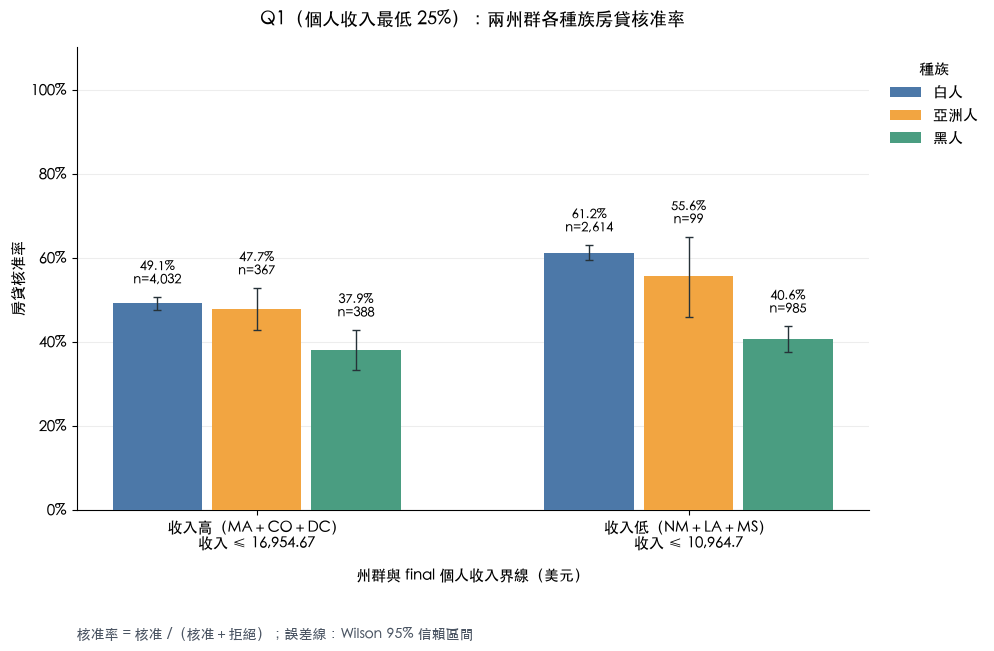

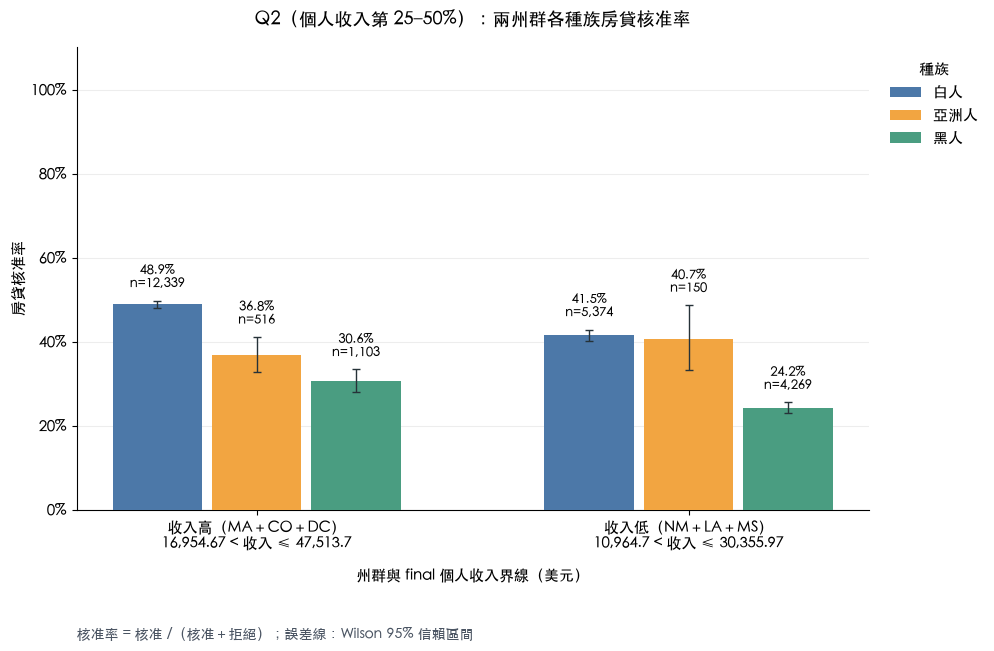

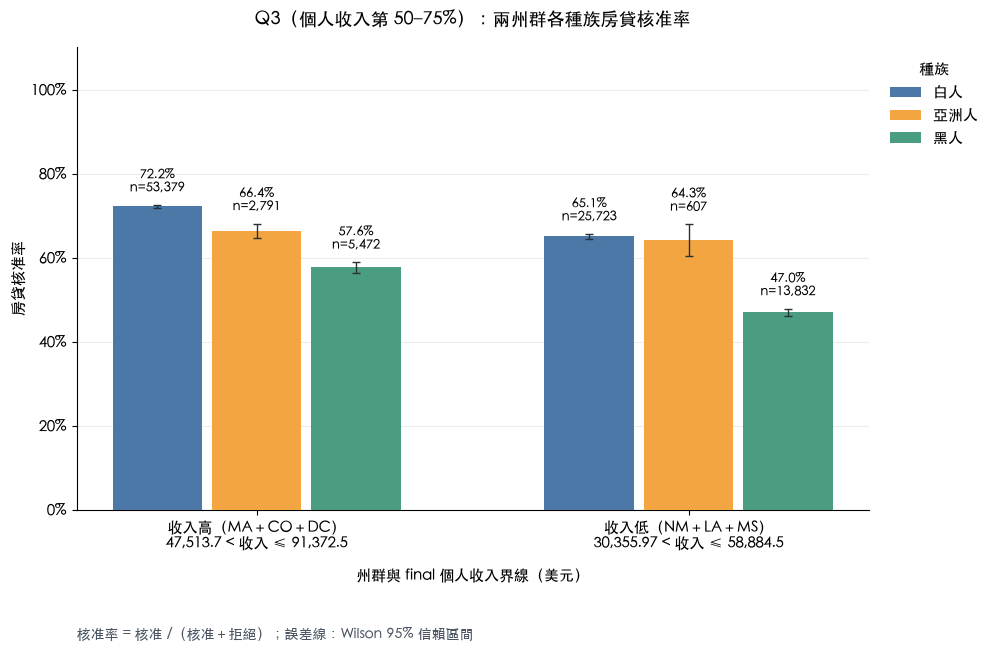

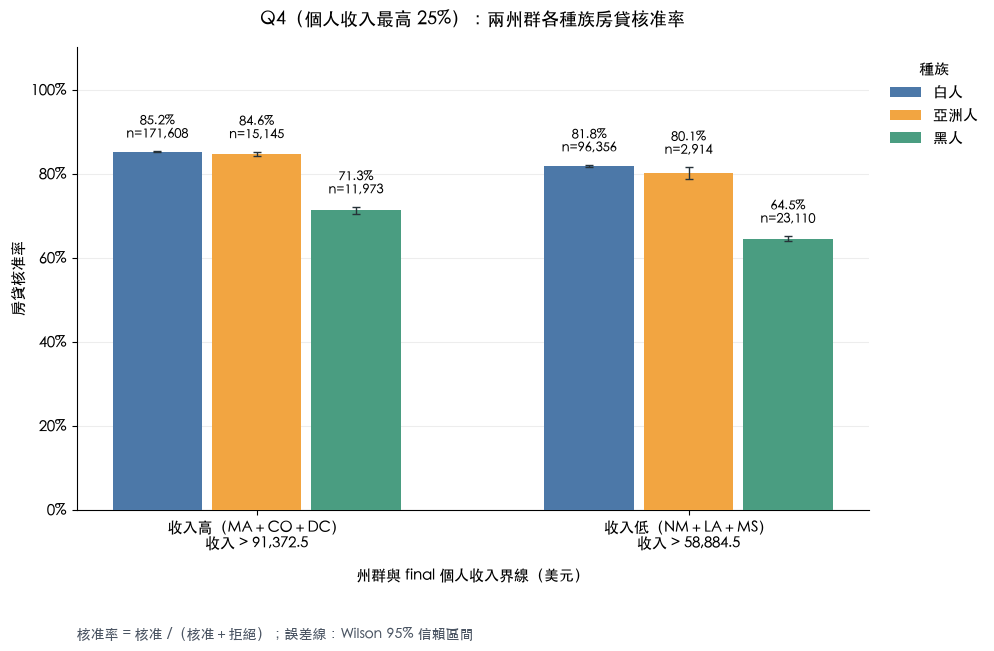

In [5]:
group_labels={groups[0]:'收入高（MA＋CO＋DC）',groups[1]:'收入低（NM＋LA＋MS）'}
colors=['#4C78A8','#F2A541','#4A9D81']
race_labels=['白人','亞洲人','黑人']
quartile_labels={'Q1':'個人收入最低 25%','Q2':'個人收入第 25–50%','Q3':'個人收入第 50–75%','Q4':'個人收入最高 25%'}
def income_range(state,q):
    a,b,c=[f'{v*1000:,.3f}'.rstrip('0').rstrip('.') for v in cutoffs.loc[state]]
    return {'Q1':f'收入 ≤ {a}', 'Q2':f'{a} < 收入 ≤ {b}', 'Q3':f'{b} < 收入 ≤ {c}', 'Q4':f'收入 > {c}'}[q]
def draw_chart(ax,q):
    width=.23
    for j,(race,label,color) in enumerate(zip(races,race_labels,colors)):
        group=summary.xs((q,race),level=('income_quartile','derived_race')).reindex(groups)
        x=np.arange(2)+(j-1)*width
        for k,row in enumerate(group.itertuples()):
            if row.n==0:
                ax.text(x[k],.025,'無樣本',ha='center',fontsize=9)
                continue
            ax.bar(x[k],row.approval_rate,width*.9,color=color,label=label if k==0 else None,zorder=3)
            ax.errorbar(x[k],row.approval_rate,yerr=[[max(0,row.approval_rate-row.ci95_low)],[max(0,row.ci95_high-row.approval_rate)]],fmt='none',ecolor='#263238',capsize=3,lw=1,zorder=4)
            ax.text(x[k],min(.99,row.ci95_high+.025),f'{row.approval_rate:.1%}\nn={row.n:,}',ha='center',va='bottom',fontsize=9)
    ax.set_title(f'{q}（{quartile_labels[q]}）：兩州群各種族房貸核准率',fontsize=13,pad=16)
    ax.set_xticks([0,1], [f'{group_labels[s]}\n{income_range(s,q)}' for s in groups])
    ax.set_xlabel('州群與 final 個人收入界線（美元）',labelpad=12)
    ax.set_ylabel('房貸核准率')
    ax.set_ylim(0,1.1)
    ax.set_yticks(np.arange(0,1.01,.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.22,zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(title='種族',loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
for q in ['Q1','Q2','Q3','Q4']:
    fig,ax=plt.subplots(figsize=(11,7))
    draw_chart(ax,q)
    fig.text(.1,.025,'核准率 = 核准 /（核准＋拒絕）；誤差線：Wilson 95% 信賴區間',fontsize=10,color='#4b5563')
    fig.subplots_adjust(left=.1,right=.82,bottom=.21,top=.87)
    fig.savefig(assets/f'{q}_approval_rate.png',dpi=180,facecolor='white')
    plt.show()
    plt.close(fig)
# A combined overview supports easy comparison; the four separate files are also saved.
fig,axes=plt.subplots(2,2,figsize=(19,13))
for ax,q in zip(axes.flat,['Q1','Q2','Q3','Q4']):
    draw_chart(ax,q)
fig.subplots_adjust(left=.06,right=.92,bottom=.13,top=.93,wspace=.44,hspace=.58)
fig.text(.06,.025,'門檻：[final]individual_income_quartiles_by_group.csv（final 州群個人收入）；核准 = action_taken 1、2；拒絕 = 3；誤差線：Wilson 95% 信賴區間',fontsize=10)
fig.savefig(assets/'all_quartiles.png',dpi=150,facecolor='white')
plt.close(fig)


兩群各以申請紀錄數加權合併，並非州核准率的簡單平均；高收入組以 CO、MA 申請數較多，低收入組以 LA、MS 較多。兩州群收入門檻不同，同一 Q1–Q4 不代表完全相同美元收入。門檻來自一般個人，而非房貸申請人的收入分位數。房貸資料年份尚未確認，不能假定與 2024 ACS 同期。收入缺失排除可能影響組成，Wilson 區間未調整同機構或重複申請相關性。圖表未控制州別、信用或貸款條件，不推論歧視或因果效果。作者待確認。


In [6]:
for q in ['Q1','Q2','Q3','Q4']:
    lines=[]
    for race,label in zip(races,race_labels):
        high=summary.loc[(q,groups[0],race),'approval_rate']
        low=summary.loc[(q,groups[1],race),'approval_rate']
        lines.append(f'{label}：高收入組 {high:.1%}、低收入組 {low:.1%}（高−低 {(high-low)*100:+.1f} 個百分點）')
    display(Markdown(f'**{q}**：'+'；'.join(lines)+'。'))
print(f'執行完成：來源 {len(df):,} 筆；排除無效收入 {(~finite).sum():,} 筆；分析 {len(analysis):,} 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。')


**Q1**：白人：高收入組 49.1%、低收入組 61.2%（高−低 -12.1 個百分點）；亞洲人：高收入組 47.7%、低收入組 55.6%（高−低 -7.9 個百分點）；黑人：高收入組 37.9%、低收入組 40.6%（高−低 -2.7 個百分點）。

**Q2**：白人：高收入組 48.9%、低收入組 41.5%（高−低 +7.4 個百分點）；亞洲人：高收入組 36.8%、低收入組 40.7%（高−低 -3.8 個百分點）；黑人：高收入組 30.6%、低收入組 24.2%（高−低 +6.4 個百分點）。

**Q3**：白人：高收入組 72.2%、低收入組 65.1%（高−低 +7.1 個百分點）；亞洲人：高收入組 66.4%、低收入組 64.3%（高−低 +2.1 個百分點）；黑人：高收入組 57.6%、低收入組 47.0%（高−低 +10.6 個百分點）。

**Q4**：白人：高收入組 85.2%、低收入組 81.8%（高−低 +3.4 個百分點）；亞洲人：高收入組 84.6%、低收入組 80.1%（高−低 +4.6 個百分點）；黑人：高收入組 71.3%、低收入組 64.5%（高−低 +6.8 個百分點）。

執行完成：來源 470,123 筆；排除無效收入 14,977 筆；分析 455,146 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。


### 核准率差異的 p-value 檢查（2026-11-17）

依使用者要求，檢查兩種比較：同一收入組、同種族比較兩州群（12 組）；同一收入組、同州群做三種族兩兩比較（24 組）。使用與圖相同的有效申請與核准定義，虛無假設為兩者核准率相等，採**雙尾兩比例 z 檢定（虛無假設下合併比例）**。這是二元核准結果的比例檢定；未做控制變數迴歸。以每張圖全部 36 組為一個檢定家族，並列原始 p-value 與 Holm 校正值，顯著性以校正後 p < 0.05 判讀；未對兩張圖合計 72 組作共同校正。

圖上的 Wilson 95% 信賴區間是各柱子的區間，不能直接以區間是否重疊取代差異檢定。下表保留各組核准筆數、N、核准率及有方向的百分點差異；核對各比較的期望次數至少為 5，才採用常態近似。

檢定假設各申請紀錄獨立，未調整同機構、同州或同一申請人造成的相關性；目前資料缺少可確認的申請人與機構識別，p-value 為此假設下的結果。州群採不同收入門檻，同一 Q 並非相同美元收入；顯著差異也不代表歧視或因果效果。

In [7]:
from itertools import combinations
from math import erfc, sqrt

# Two-sided pooled two-proportion z test; each application is treated as independent.
rows=[]
def compare(q, kind, label, a, b):
    x1,n1,x2,n2=int(a.approved_n),int(a.n),int(b.approved_n),int(b.n)
    p1,p2=x1/n1,x2/n2
    pooled=(x1+x2)/(n1+n2)
    se=sqrt(pooled*(1-pooled)*(1/n1+1/n2))
    zstat=(p1-p2)/se
    expected_min=min(n1*pooled,n1*(1-pooled),n2*pooled,n2*(1-pooled))
    assert expected_min>=5, 'Small expected counts: use an exact test instead.'
    rows.append({'收入組':q,'比較類型':kind,'比較（前者−後者）':label,
                 '前者核准筆數':x1,'前者N':n1,'後者核准筆數':x2,'後者N':n2,
                 '前者核准率':p1,'後者核准率':p2,'差異（百分點）':100*(p1-p2),
                 'z':zstat,'p_value':erfc(abs(zstat)/sqrt(2)),
                 '最小期望次數':expected_min})
for q in ['Q1','Q2','Q3','Q4']:
    for race,label in zip(races,race_labels):
        compare(q,'同種族跨州群',label+'：'+group_labels[groups[0]]+' − '+group_labels[groups[1]],
                summary.loc[(q,groups[0],race)],summary.loc[(q,groups[1],race)])
    for group in groups:
        for i,j in combinations(range(3),2):
            compare(q,'同州群跨種族',group_labels[group]+'：'+race_labels[i]+' − '+race_labels[j],
                    summary.loc[(q,group,races[i])],summary.loc[(q,group,races[j])])
pvalue_results=pd.DataFrame(rows)
# One Holm family contains all 36 comparisons within this figure.
order=np.argsort(pvalue_results.p_value.to_numpy(),kind='stable')
adjusted=np.empty(len(order))
adjusted[order]=np.minimum(1,np.maximum.accumulate(
    pvalue_results.p_value.to_numpy()[order]*(len(order)-np.arange(len(order)))))
pvalue_results['p_holm']=adjusted
pvalue_results['Holm後p<0.05']=pvalue_results.p_holm.lt(.05)
assert len(pvalue_results)==36
assert pvalue_results.p_holm.ge(pvalue_results.p_value-1e-15).all()
pvalue_results.to_csv(assets/'p_values.csv',index=False)
saved_p=pd.read_csv(assets/'p_values.csv')
assert len(saved_p)==36 and np.allclose(saved_p.p_holm,pvalue_results.p_holm)
for kind in ['同種族跨州群','同州群跨種族']:
    table=pvalue_results.loc[pvalue_results['比較類型'].eq(kind)]
    print(f'表 7：{kind}；共 {len(table)} 組比較，各列 N 見表；差異為前者減後者')
    formatted=table.copy()
    for col,fmt in {'前者核准率':'{:.2%}','後者核准率':'{:.2%}',
        '差異（百分點）':'{:+.2f}','z':'{:.3f}','p_value':'{:.4g}',
        'p_holm':'{:.4g}','最小期望次數':'{:.2f}'}.items():
        formatted[col]=formatted[col].map(fmt.format)
    with pd.option_context('display.max_columns',None,'display.max_rows',None):
        display(formatted)
    print('原始 p<0.05：',int(table.p_value.lt(.05).sum()),
          '；Holm 校正後 p<0.05：',int(table.p_holm.lt(.05).sum()))
print('所有比較的最小期望次數：',pvalue_results['最小期望次數'].min())


表 7：同種族跨州群；共 12 組比較，各列 N 見表；差異為前者減後者


,收入組,比較類型,比較（前者−後者）,前者核准筆數,前者N,後者核准筆數,後者N,前者核准率,後者核准率,差異（百分點）,z,p_value,最小期望次數,p_holm,Holm後p<0.05
0,Q1,同種族跨州群,白人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,1980,4032,1599,2614,49.11%,61.17%,-12.06,-9.637,5.596e-22,1206.31,1.287e-20,True
1,Q1,同種族跨州群,亞洲人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,175,367,55,99,47.68%,55.56%,-7.87,-1.390,0.1645,48.86,1,False
2,Q1,同種族跨州群,黑人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,147,388,400,985,37.89%,40.61%,-2.72,-0.928,0.3535,154.58,1,False
9,Q2,同種族跨州群,白人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,6031,12339,2231,5374,48.88%,41.51%,+7.36,9.030,1.713e-19,2506.63,3.769e-18,True
10,Q2,同種族跨州群,亞洲人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,190,516,61,150,36.82%,40.67%,-3.84,-0.855,0.3924,56.53,1,False
11,Q2,同種族跨州群,黑人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,337,1103,1033,4269,30.55%,24.20%,+6.36,4.317,1.583e-05,281.29,0.0002375,True
18,Q3,同種族跨州群,白人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,38517,53379,16735,25723,72.16%,65.06%,+7.10,20.381,2.47e-92,7755.73,7.409e-91,True
19,Q3,同種族跨州群,亞洲人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,1852,2791,390,607,66.36%,64.25%,+2.11,0.992,0.321,206.50,1,False
20,Q3,同種族跨州群,黑人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,3153,5472,6501,13832,57.62%,47.00%,+10.62,13.301,2.285e-40,2735.43,6.169e-39,True
27,Q4,同種族跨州群,白人：收入高（MA＋CO＋DC） − 收入低（NM＋LA＋MS）,146198,171608,78846,96356,85.19%,81.83%,+3.37,22.793,5.437e-115,15433.41,1.74e-113,True


原始 p<0.05： 8 ；Holm 校正後 p<0.05： 8
表 7：同州群跨種族；共 24 組比較，各列 N 見表；差異為前者減後者


,收入組,比較類型,比較（前者−後者）,前者核准筆數,前者N,後者核准筆數,後者N,前者核准率,後者核准率,差異（百分點）,z,p_value,最小期望次數,p_holm,Holm後p<0.05
3,Q1,同州群跨種族,收入高（MA＋CO＋DC）：白人 − 亞洲人,1980,4032,175,367,49.11%,47.68%,+1.42,0.522,0.6016,179.79,1,False
4,Q1,同州群跨種族,收入高（MA＋CO＋DC）：白人 − 黑人,1980,4032,147,388,49.11%,37.89%,+11.22,4.225,2.391e-05,186.71,0.0003347,True
5,Q1,同州群跨種族,收入高（MA＋CO＋DC）：亞洲人 − 黑人,175,367,147,388,47.68%,37.89%,+9.80,2.721,0.006517,156.52,0.07821,False
6,Q1,同州群跨種族,收入低（NM＋LA＋MS）：白人 − 亞洲人,1599,2614,55,99,61.17%,55.56%,+5.62,1.124,0.2609,38.64,1,False
7,Q1,同州群跨種族,收入低（NM＋LA＋MS）：白人 − 黑人,1599,2614,400,985,61.17%,40.61%,+20.56,11.068,1.803e-28,437.90,4.328e-27,True
8,Q1,同州群跨種族,收入低（NM＋LA＋MS）：亞洲人 − 黑人,55,99,400,985,55.56%,40.61%,+14.95,2.872,0.004073,41.55,0.05294,False
12,Q2,同州群跨種族,收入高（MA＋CO＋DC）：白人 − 亞洲人,6031,12339,190,516,48.88%,36.82%,+12.06,5.369,7.924e-08,249.71,1.347e-06,True
13,Q2,同州群跨種族,收入高（MA＋CO＋DC）：白人 − 黑人,6031,12339,337,1103,48.88%,30.55%,+18.32,11.678,1.657e-31,522.53,4.142e-30,True
14,Q2,同州群跨種族,收入高（MA＋CO＋DC）：亞洲人 − 黑人,190,516,337,1103,36.82%,30.55%,+6.27,2.508,0.01213,167.96,0.1334,False
15,Q2,同州群跨種族,收入低（NM＋LA＋MS）：白人 − 亞洲人,2231,5374,61,150,41.51%,40.67%,+0.85,0.208,0.8353,62.24,1,False


原始 p<0.05： 19 ；Holm 校正後 p<0.05： 15
所有比較的最小期望次數： 37.13509843856076


### p-value 檢查結果

2026-11-17 已從乾淨 Jupyter kernel 執行全部程式，確認來源檔 SHA-256、分組筆數與 CSV 結果一致。採每張圖 36 次比較的 Holm 校正，顯著水準 0.05。

- **同種族跨州群**：原始 p < 0.05 共 8/12 組；Holm 校正後共 **8/12 組**。
- **同州群跨種族**：原始 p < 0.05 共 19/24 組；Holm 校正後共 **15/24 組**。

完整數值見 [p_values.csv](assets/income_groups_mortgage_approval/p_values.csv)，包含各組 N、核准筆數、核准率、百分點差異、原始與校正後 p-value。未達顯著表示目前檢定證據不足，並不證明兩組相同。原圖仍顯示核准率與 Wilson 95% 信賴區間；本次 p-value 放在上述表格，未把 36 組比較擠入圖中。成果尚待學生自行檢閱與提交。
